In [1]:
import os
import pandas as pd
import kagglehub

# 1. Завантаження датасету
path = kagglehub.dataset_download("muratkokludataset/dry-bean-dataset")
print("Path to dataset files:", path)

# 2. Знаходимо всі файли в завантаженій директорії
all_files = []
for root, dirs, files in os.walk(path):
    for file in files:
        all_files.append(os.path.join(root, file))

print("Знайдені файли:", all_files)

# 3. Шукаємо CSV або Excel файл і зчитуємо його
data_file = [f for f in all_files if f.endswith(('.csv', '.xlsx', '.xls'))][0]

if data_file.endswith('.csv'):
    df = pd.read_csv(data_file)
else:
    # Для формату .xlsx потрібен openpyxl (зазвичай встановлений у Colab)
    df = pd.read_excel(data_file)

# 4. Перевірка результату
df.head()

Using Colab cache for faster access to the 'dry-bean-dataset' dataset.
Path to dataset files: /kaggle/input/dry-bean-dataset
Знайдені файли: ['/kaggle/input/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset_Citation_Request.txt', '/kaggle/input/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset.xlsx', '/kaggle/input/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset.arff']


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


# Практичне завдання №2: Логістична регресія та федеративне навчання

## Етап 1. Дослідження даних та попередня обробка (EDA & Preprocessing)

### 1.1 Первинний аналіз даних
На цьому етапі проводимо огляд структури датасету Dry Bean Dataset:
- Перевірка наявності пропущених значень;
- Аналіз типів даних та основних статистичних характеристик;
- Дослідження розподілу цільової змінної (Class);
- Візуалізація кореляційної матриці для виявлення мультиколінеарності між ознаками.

=== 1. Основна інформація про датасет ===
Розмірність датасету: 13611 рядків, 17 стовпчиків

Типи даних та пропущені значення:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 

/tmp/ipykernel_1885/4164905092.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Class', palette='viridis', order=class_counts.index)


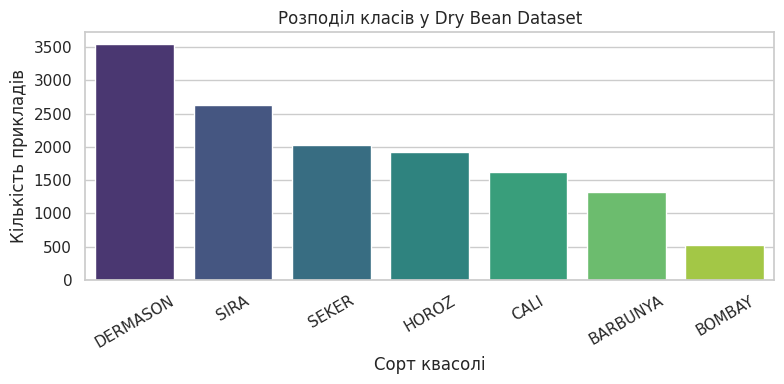


=== 4. Основні статистики числових ознак ===


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


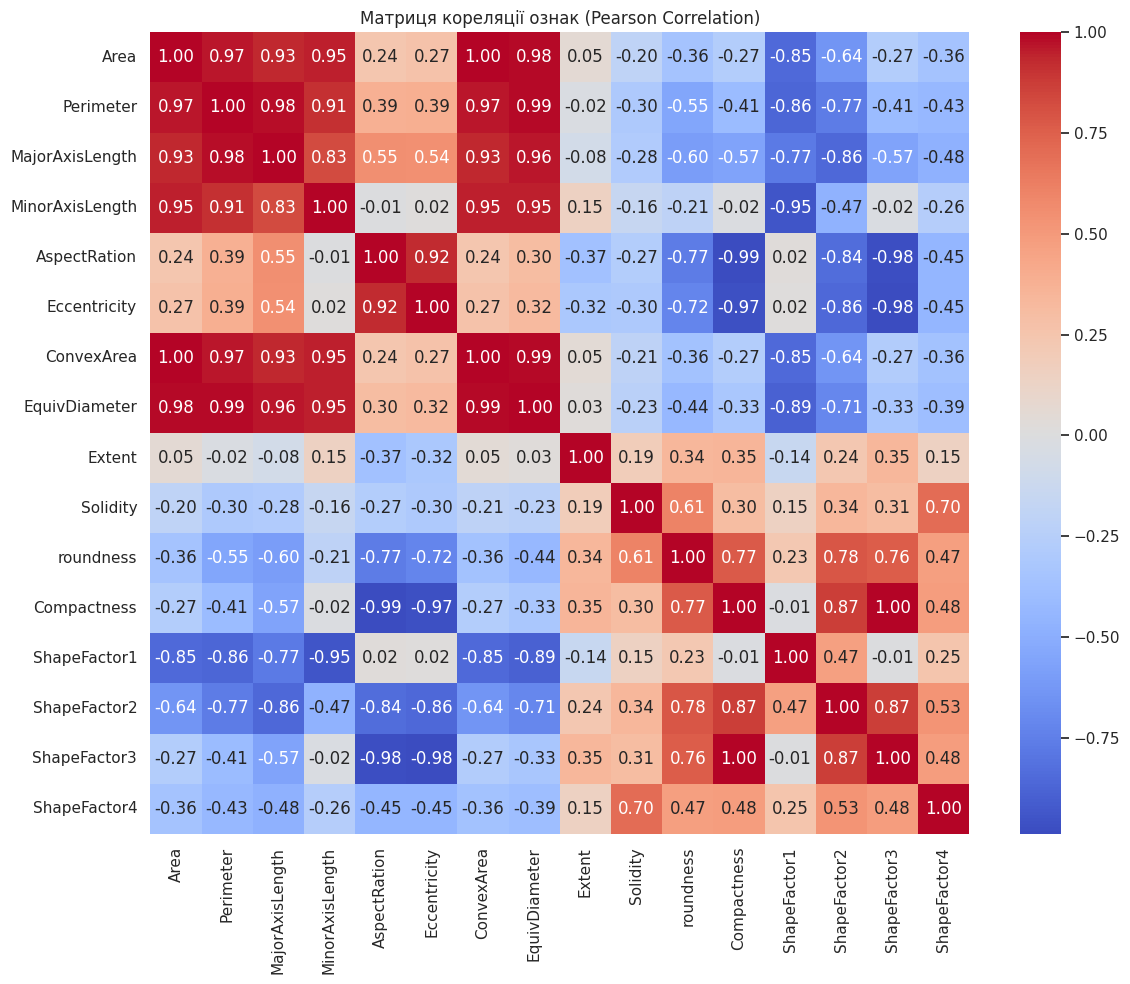

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Налаштування стилю графіків
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("=== 1. Основна інформація про датасет ===")
print(f"Розмірність датасету: {df.shape[0]} рядків, {df.shape[1]} стовпчиків\n")
print("Типи даних та пропущені значення:")
print(df.info())

print("\n=== 2. Кількість пропущених значень ===")
print(df.isnull().sum())

print("\n=== 3. Розподіл цільової змінної (Class) ===")
class_counts = df['Class'].value_counts()
print(class_counts)

# Візуалізація розподілу класів
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='Class', palette='viridis', order=class_counts.index)
plt.title("Розподіл класів у Dry Bean Dataset")
plt.xlabel("Сорт квасолі")
plt.ylabel("Кількість прикладів")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("\n=== 4. Основні статистики числових ознак ===")
display(df.describe().T)

# Візуалізація кореляційної матриці
plt.figure(figsize=(12, 10))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Матриця кореляції ознак (Pearson Correlation)")
plt.tight_layout()
plt.show()

### 1.2 Обґрунтування стратегії розбиття даних та запобігання Data Leakage

#### Що таке Data Leakage (витік даних)?
**Data Leakage** — це ситуація, коли інформація з валідаційної або тестової вибірки потрапляє в модель під час її навчання чи попередньої обробки даних (наприклад, під час нормалізації/стандартизації або відбору ознак). Це призводить до занадто оптимістичних оцінок якості моделі під час розробки та суттєвого падіння точності на реальних нових даних.

#### Чому розбиття даних потрібно виконувати ДО масштабування чи кодування?
Якщо обчислити середнє значення ($\mu$) та стандартне відхилення ($\sigma$) для нормалізації/стандартизації на всьому датасеті (включаючи Val та Test), параметри тестових даних вплинуть на процес масштабування навчальних даних.
Тому правильний порядок дії такий:
1. Спочатку здійснюємо розбиття датасету на FL Train Pool, Global Validation та Global Test.
2. Скалер (StandardScaler) навчається (fit) **виключно** на FL Train Poo`.
3. Застосовуємо зафіксовані параметри скалера (transform) до валідаційної та тестової множин.

#### Схема розбиття вибірки:
- **Global Test (15%)**: зберігається на сервері, використовується лише для фінальної оцінки моделі.
- **Global Validation (15%)**: використовується для моніторингу та підбору гіперпараметрів.
- **FL Train Pool (70%)**: решта даних, які будуть розподілятися між клієнтами у федеративному навчанні.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# 1. Відокремлення ознак та цільової змінної
X = df.drop(columns=['Class']).copy()
y = df['Class'].copy()

# 2. Кодування цільової змінної у числові мітки (0..C-1)
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
class_names = label_encoder.classes_
num_classes = len(class_names)

print(f"Знайдено класів ({num_classes}): {class_names}\n")

# 3. Стратифіковане розбиття:
# Спочатку відокремлюємо Global Test (15%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y_encoded, test_size=0.15, stratify=y_encoded, random_state=42
)

# З решти (85%) відокремлюємо Global Validation (15% від загальної кількості -> 0.15 / 0.85 ≈ 0.1765)
val_relative_size = 0.15 / 0.85
X_train_pool, X_val, y_train_pool, y_val = train_test_split(
    X_temp, y_temp, test_size=val_relative_size, stratify=y_temp, random_state=42
)

print(f"Розміри отриманих множин:")
print(f"• FL Train Pool:      {X_train_pool.shape[0]} об'єктів ({X_train_pool.shape[0]/len(df):.1%})")
print(f"• Global Validation:  {X_val.shape[0]} об'єктів ({X_val.shape[0]/len(df):.1%})")
print(f"• Global Test:        {X_test.shape[0]} об'єктів ({X_test.shape[0]/len(df):.1%})\n")

# 4. Масштабування ознак (StandardScaler)
scaler = StandardScaler()

# Навчаємо скалер ЛИШЕ на FL Train Pool
X_train_pool_scaled = scaler.fit_transform(X_train_pool)

# Трансформуємо Validation та Test параметрами з Train Pool
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Масштабування (StandardScaler) успішно виконано без витоку даних (Data Leakage)!")

Знайдено класів (7): ['BARBUNYA' 'BOMBAY' 'CALI' 'DERMASON' 'HOROZ' 'SEKER' 'SIRA']

Розміри отриманих множин:
• FL Train Pool:      9527 об'єктів (70.0%)
• Global Validation:  2042 об'єктів (15.0%)
• Global Test:        2042 об'єктів (15.0%)

Масштабування (StandardScaler) успішно виконано без витоку даних (Data Leakage)!


# Етап 2. Реалізація багатокласової логістичної регресії засобами NumPy

На цьому етапі ми створюємо власний клас логістичної регресії з нуля. Всі математичні обчислення виконуються векторизовано через бібліотеку NumPy, без використання циклів по окремих прикладах вибірки.

### Математична модель та алгоритм:
1. Лінійна комбінація: Z = X * W + b
2. Обчислення ймовірностей (Softmax): для числової стабільності від кожного рядка матриці Z віднімається його максимальне значення, що запобігає переповненню типу даних float при піднесенні до степеня e.
3. Cross-Entropy Loss з Ridge-регуляризацією (L2): функція втрат оцінює розходження між передбаченими ймовірностями та true one-hot мітками. Регуляризація додається лише для матриці ваг W, параметр зміщення b не регуляризується.
4. Обчислення градієнтів: знаходяться аналітичні похідні функції втрат по W та b для оновлення параметрів на кожному кроці міні-батчевого градієнтного спуску.

In [4]:
import numpy as np

class MulticlassLogisticRegression:
    def __init__(self, l2_coef=0.01, learning_rate=0.01, batch_size=64, epochs=100, random_state=42):
        self.l2_coef = l2_coef
        self.lr = learning_rate
        self.batch_size = batch_size
        self.epochs = epochs
        self.random_state = random_state

        self.W = None
        self.b = None
        self.loss_history = []

    def _one_hot(self, y, num_classes):
        """Перетворення вектора міток у one-hot матрицю."""
        m = len(y)
        one_hot = np.zeros((m, num_classes))
        one_hot[np.arange(m), y] = 1.0
        return one_hot

    def softmax(self, Z):
        """
        Чисельно стабільна функція Softmax.
        Віднімаємо максимум по кожному рядку для уникнення overflow.
        """
        max_Z = np.max(Z, axis=1, keepdims=True)
        exp_Z = np.exp(Z - max_Z)
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

    def predict_proba(self, X):
        """Обчислення ймовірностей належності до кожного класу."""
        Z = np.dot(X, self.W) + self.b
        return self.softmax(Z)

    def predict(self, X):
        """Передбачення класу з найвищою ймовірністю."""
        probs = self.predict_proba(X)
        return np.argmax(probs, axis=1)

    def compute_loss(self, X, Y_one_hot):
        """
        Обчислення Cross-Entropy Loss з Ridge (L2) регуляризацією.
        Y_one_hot: one-hot закодована матриця цільових класів.
        """
        m = X.shape[0]
        probs = self.predict_proba(X)

        # Додаємо epsilon для уникнення log(0)
        eps = 1e-15
        probs_clipped = np.clip(probs, eps, 1 - eps)

        # Крос-ентропія
        cross_entropy = - (1.0 / m) * np.sum(Y_one_hot * np.log(probs_clipped))

        # L2 регуляризація ваг W (без урахування b)
        l2_penalty = (self.l2_coef / 2.0) * np.sum(self.W ** 2)

        return cross_entropy + l2_penalty

    def compute_gradients(self, X_batch, Y_batch_one_hot):
        """Векторизоване обчислення градієнтів для W та b."""
        m = X_batch.shape[0]
        probs = self.predict_proba(X_batch)
        error = probs - Y_batch_one_hot

        # Градієнти за формулами з методички
        grad_W = (1.0 / m) * np.dot(X_batch.T, error) + self.l2_coef * self.W
        grad_b = (1.0 / m) * np.sum(error, axis=0, keepdims=True)

        return grad_W, grad_b

    def fit(self, X, y, X_val=None, y_val=None, verbose=False):
        """
        Навчання моделі за допомогою міні-батчевого градієнтного спуску.
        """
        np.random.seed(self.random_state)
        m, d = X.shape
        num_classes = len(np.unique(y)) if y_val is None else max(len(np.unique(y)), len(np.unique(y_val)))

        # Ініціалізація ваг та зміщень
        self.W = np.random.randn(d, num_classes) * 0.01
        self.b = np.zeros((1, num_classes))

        Y_one_hot = self._one_hot(y, num_classes)
        self.loss_history = []

        for epoch in range(self.epochs):
            # Перемішування даних на початку кожної епохи
            indices = np.random.permutation(m)
            X_shuffled = X[indices]
            Y_shuffled = Y_one_hot[indices]

            # Навчання по міні-батчах
            for i in range(0, m, self.batch_size):
                X_batch = X_shuffled[i:i + self.batch_size]
                Y_batch = Y_shuffled[i:i + self.batch_size]

                grad_W, grad_b = self.compute_gradients(X_batch, Y_batch)

                # Оновлення параметрів
                self.W -= self.lr * grad_W
                self.b -= self.lr * grad_b

            current_loss = self.compute_loss(X, Y_one_hot)
            self.loss_history.append(current_loss)

            if verbose and (epoch + 1) % 10 == 0:
                val_str = ""
                if X_val is not None and y_val is not None:
                    y_val_oh = self._one_hot(y_val, num_classes)
                    val_loss = self.compute_loss(X_val, y_val_oh)
                    val_str = f" | Val Loss: {val_loss:.4f}"
                print(f"Epoch {epoch + 1}/{self.epochs} - Loss: {current_loss:.4f}{val_str}")

        return self

# Перевірка працездатності класу на вибірці
print("Тестова перевірка створеного класу:")
demo_model = MulticlassLogisticRegression(epochs=20, learning_rate=0.1, batch_size=128)
demo_model.fit(X_train_pool_scaled, y_train_pool, verbose=True)

test_preds = demo_model.predict(X_val_scaled[:5])
print("Передбачені класи для перших 5 об'єктів:", test_preds)
print("Реальні класи для перших 5 об'єктів:    ", y_val[:5])

Тестова перевірка створеного класу:
Epoch 10/20 - Loss: 0.4473
Epoch 20/20 - Loss: 0.4419
Передбачені класи для перших 5 об'єктів: [5 3 2 3 5]
Реальні класи для перших 5 об'єктів:     [5 3 2 3 5]


# Етап 3. Центрально навчана базова модель (Centralized Baseline)

На цьому етапі ми навчаємо логістичну регресію на всіх централізованих даних (FL Train Pool). Ця модель слугує базовою лінією (baseline) для подальшого порівняння з локальними та федеративними моделями.

### Основні кроки виконання:
1. Підбір оптимальних гіперпараметрів (параметр L2-регуляризації, швидкість навчання learning rate) за допомогою валідаційної вибірки Global Validation.
2. Фінальне оцінювання якості найкращої моделі виключно на Global Test.
3. Розрахунок ключових метрик класифікації: Accuracy, Macro-F1, Balanced Accuracy та Log-Loss.
4. Побудова матриці помилок (Confusion Matrix) та графіка функції втрат по епохах.

=== Пошук гіперпараметрів на Global Validation ===
lr=0.1   | l2=0.1   -> Val Loss: 0.8561 | Val Accuracy: 0.8981
lr=0.1   | l2=0.01  -> Val Loss: 0.4238 | Val Accuracy: 0.9270
lr=0.1   | l2=0.001 -> Val Loss: 0.2550 | Val Accuracy: 0.9339
lr=0.05  | l2=0.1   -> Val Loss: 0.8558 | Val Accuracy: 0.8991
lr=0.05  | l2=0.01  -> Val Loss: 0.4249 | Val Accuracy: 0.9270
lr=0.05  | l2=0.001 -> Val Loss: 0.2551 | Val Accuracy: 0.9314
lr=0.01  | l2=0.1   -> Val Loss: 0.8585 | Val Accuracy: 0.9035
lr=0.01  | l2=0.01  -> Val Loss: 0.4335 | Val Accuracy: 0.9241
lr=0.01  | l2=0.001 -> Val Loss: 0.2910 | Val Accuracy: 0.9265

Найкращі гіперпараметри: {'learning_rate': 0.1, 'l2_coef': 0.001} з Val Loss = 0.2550

=== Метрики централізованої моделі на Global Test ===


,Model,Accuracy,Macro-F1,Balanced Accuracy,Log-Loss
0,Centralized Baseline,0.919197,0.931518,0.929974,0.228838


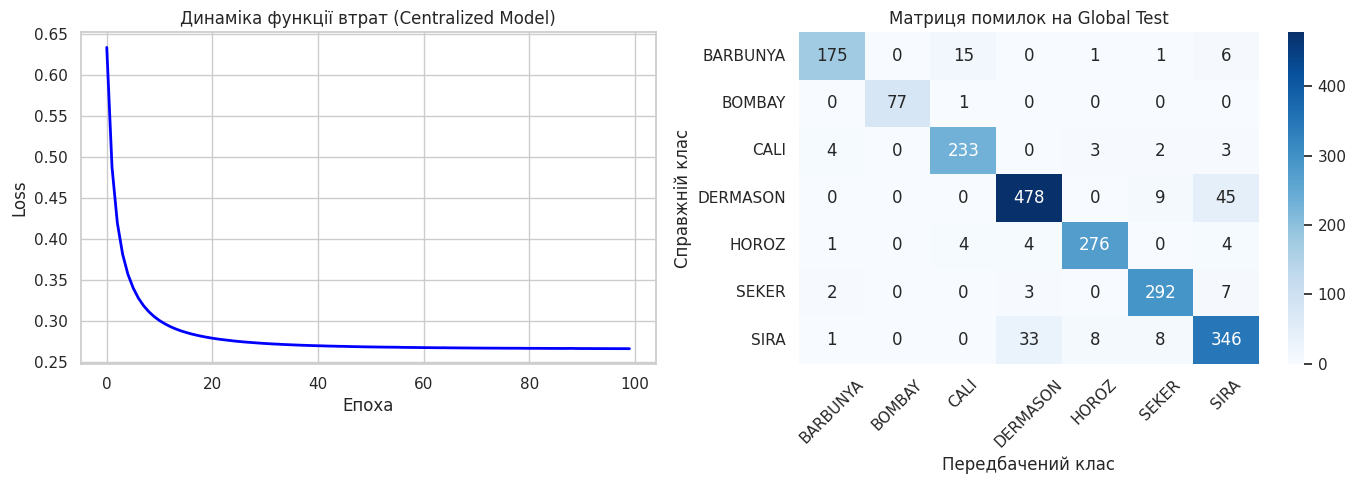

In [5]:
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, log_loss, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1. Пошук кращих гіперпараметрів на Global Validation
learning_rates = [0.1, 0.05, 0.01]
l2_coefs = [0.1, 0.01, 0.001]
batch_size = 128
epochs = 100

best_val_loss = float('inf')
best_params = {}
best_model = None

print("=== Пошук гіперпараметрів на Global Validation ===")
for lr in learning_rates:
    for l2 in l2_coefs:
        model = MulticlassLogisticRegression(
            l2_coef=l2,
            learning_rate=lr,
            batch_size=batch_size,
            epochs=epochs,
            random_state=42
        )
        model.fit(X_train_pool_scaled, y_train_pool, verbose=False)

        # Обчислення втрат на валідації
        y_val_oh = model._one_hot(y_val, num_classes)
        val_loss = model.compute_loss(X_val_scaled, y_val_oh)

        y_val_pred = model.predict(X_val_scaled)
        val_acc = accuracy_score(y_val, y_val_pred)

        print(f"lr={lr:<5} | l2={l2:<5} -> Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_params = {'learning_rate': lr, 'l2_coef': l2}
            best_model = model

print(f"\nНайкращі гіперпараметри: {best_params} з Val Loss = {best_val_loss:.4f}\n")

# 2. Фінальна оцінка централізованої моделі на Global Test
y_test_pred = best_model.predict(X_test_scaled)
y_test_proba = best_model.predict_proba(X_test_scaled)

acc = accuracy_score(y_test, y_test_pred)
f1_macro = f1_score(y_test, y_test_pred, average='macro')
bal_acc = balanced_accuracy_score(y_test, y_test_pred)
loss_test = log_loss(y_test, y_test_proba)

# Зберігаємо результати для порівняльної таблиці у наступних етапах
centralized_metrics = {
    'Model': 'Centralized Baseline',
    'Accuracy': acc,
    'Macro-F1': f1_macro,
    'Balanced Accuracy': bal_acc,
    'Log-Loss': loss_test
}

metrics_df = pd.DataFrame([centralized_metrics])
print("=== Метрики централізованої моделі на Global Test ===")
display(metrics_df)

# 3. Візуалізація графіка навчання та матриці помилок
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Графік втрат
axes[0].plot(best_model.loss_history, color='blue', linewidth=2)
axes[0].set_title("Динаміка функції втрат (Centralized Model)")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Loss")
axes[0].grid(True)

# Матриця помилок
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_title("Матриця помилок на Global Test")
axes[1].set_xlabel("Передбачений клас")
axes[1].set_ylabel("Справжній клас")
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Етап 4. Розподіл даних між клієнтами та сервером

У федеративному навчанні сервер координує процес і оцінює глобальну модель, але не має доступу до локальних вибірок клієнтів. Кожен клієнт навчає модель виключно на власних даних.

### Сценарії розподілу даних:
1. IID (Independent and Identically Distributed): дані між клієнтами розподілені рівномірно, пропорції класів у кожного клієнта відповідають глобальному розподілу.
2. Non-IID (Dirichlet Distribution): моделювання реального розподіленого середовища, де у різних клієнтів спостерігається суттєвий дисбаланс класів. Параметр альфа регулює рівень неоднорідності:
   - альфа = 5: близький до IID розподілу;
   - альфа = 1: помірна неоднорідність;
   - альфа = 0.3: сильна неоднорідність (окремі клієнти мають лише декілька класів).

=== Візуалізація розподілу класів між клієнтами ===


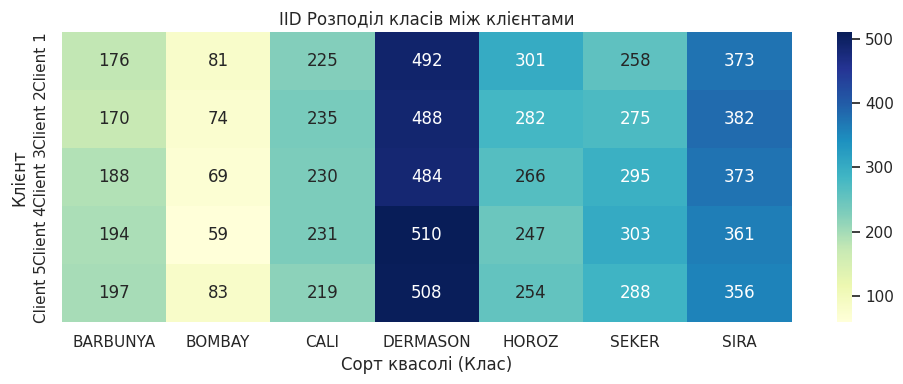

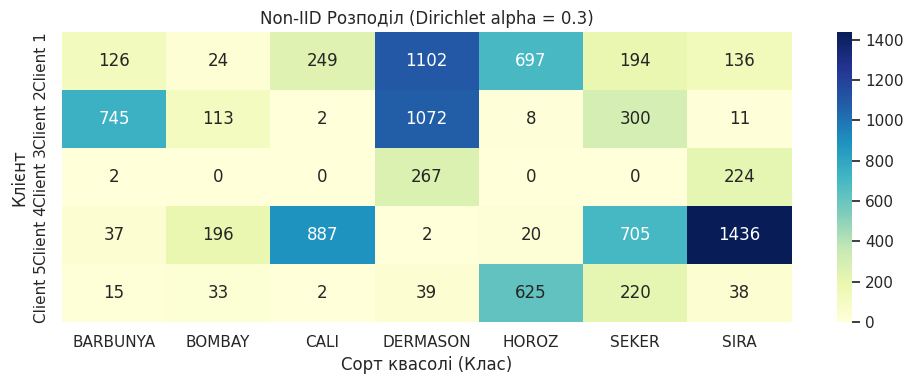

In [6]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def create_iid_splits(X, y, num_clients=5, random_state=42):
    """Розподіл даних за IID сценарієм (стратифіковано або випадково рівномірно)."""
    np.random.seed(random_state)
    indices = np.random.permutation(len(y))
    client_splits = np.array_split(indices, num_clients)

    client_data = {}
    for k in range(num_clients):
        idx = client_splits[k]
        client_data[k] = (X[idx], y[idx])
    return client_data

def create_non_iid_dirichlet_splits(X, y, num_clients=5, alpha=0.3, num_classes=7, random_state=42):
    """Розподіл даних за Non-IID сценарієм з використанням розподілу Діріхле."""
    np.random.seed(random_state)
    client_indices = [[] for _ in range(num_clients)]

    for c in range(num_classes):
        # Знаходимо індекси всіх об'єктів класу c
        idx_c = np.where(y == c)[0]
        np.random.shuffle(idx_c)

        # Ґенеруємо пропорції розподілу за допомогою Dirichlet
        proportions = np.random.dirichlet(np.repeat(alpha, num_clients))
        # Нормалізуємо, щоб сума частот давала кількість елементів
        proportions = (np.cumsum(proportions) * len(idx_c)).astype(int)[:-1]

        # Розподіляємо індекси класу c між клієнтами
        split_idx = np.split(idx_c, proportions)
        for k in range(num_clients):
            client_indices[k].extend(split_idx[k])

    client_data = {}
    for k in range(num_clients):
        idx = np.array(client_indices[k])
        np.random.shuffle(idx)
        client_data[k] = (X[idx], y[idx])
    return client_data

def plot_client_class_distribution(client_data, num_classes, title):
    """Візуалізація розподілу класів у кожного клієнта у вигляді теплової карти."""
    matrix = []
    for k in sorted(client_data.keys()):
        _, y_k = client_data[k]
        counts = [np.sum(y_k == c) for c in range(num_classes)]
        matrix.append(counts)

    df_dist = pd.DataFrame(matrix, index=[f"Client {k+1}" for k in range(len(client_data))],
                           columns=class_names)

    plt.figure(figsize=(10, 4))
    sns.heatmap(df_dist, annot=True, fmt="d", cmap="YlGnBu", cbar=True)
    plt.title(title)
    plt.xlabel("Сорт квасолі (Клас)")
    plt.ylabel("Клієнт")
    plt.tight_layout()
    plt.show()
    return df_dist

# Формуємо вибірки для 5 клієнтів
NUM_CLIENTS = 5

# 1. IID Розподіл
client_data_iid = create_iid_splits(X_train_pool_scaled, y_train_pool, num_clients=NUM_CLIENTS)

# 2. Non-IID Розподіл (alpha = 0.3)
client_data_non_iid_03 = create_non_iid_dirichlet_splits(
    X_train_pool_scaled, y_train_pool, num_clients=NUM_CLIENTS, alpha=0.3, num_classes=num_classes
)

print("=== Візуалізація розподілу класів між клієнтами ===")
dist_iid = plot_client_class_distribution(client_data_iid, num_classes, "IID Розподіл класів між клієнтами")
dist_non_iid = plot_client_class_distribution(client_data_non_iid_03, num_classes, "Non-IID Розподіл (Dirichlet alpha = 0.3)")

# Етап 5. Симуляція федеративного навчання (FedAvg)

На цьому етапі реалізується алгоритм FedAvg (Federated Averaging) для симуляції розподіленого навчання на кількох клієнтах.

### Алгоритм FedAvg та агрегація ваг:
1. Ініціалізація: Сервер створює початкову глобальну модель з вагами W та зміщенням b.
2. Локальне навчання: На кожному раунді сервер передає поточні глобальні ваги клієнтам. Кожен клієнт навчає модель протягом заданої кількості локальних епох E на своїх локальних даних.
3. Зважена агрегація: Сервер збирає оновлені ваги та обчислює нові глобальні параметри за формулою зваженого середнього. Вага кожного клієнта залежить від кількості його прикладів: n_k / N, де n_k — кількість прикладів у клієнта k, а N — загальна кількість прикладів у всіх клієнтів.
4. Оцінювання: Після кожного раунду якість глобальної моделі перевіряється на валідаційній вибірці Global Validation.

=== Запуск базової симуляції FedAvg (IID, 20 раундів, E=1) ===


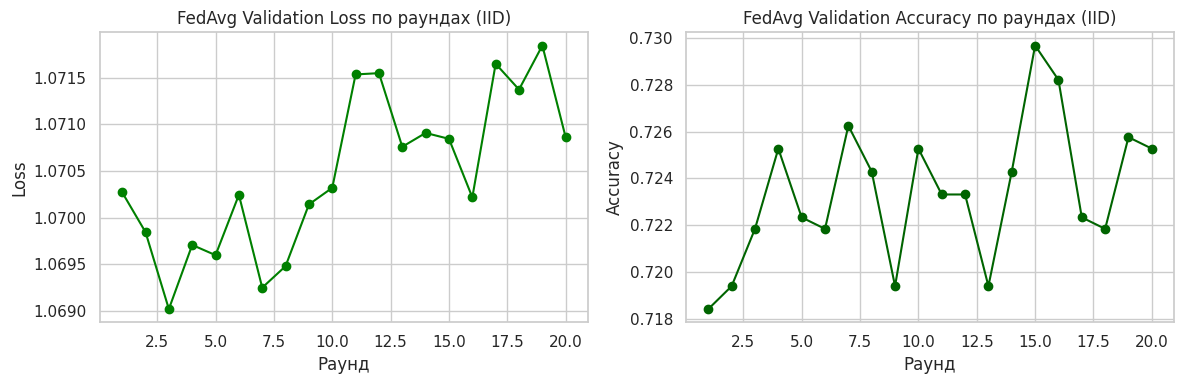

Фінальна точність на Global Validation: 0.7253


In [7]:
import numpy as np
import copy
import matplotlib.pyplot as plt

def federated_averaging(client_data, num_rounds=20, local_epochs=1, lr=0.1, l2_coef=0.001, batch_size=128, random_state=42):
    """
    Симуляція алгоритму FedAvg.

    client_data: словник {client_id: (X_k, y_k)}
    num_rounds: кількість раундів федеративного навчання
    local_epochs: кількість локальних епох навчання на кожному клієнті
    """
    np.random.seed(random_state)

    # 1. Загальні параметри
    num_clients = len(client_data)
    d = client_data[0][0].shape[1]

    # Розраховуємо вагу кожного клієнта p_k = n_k / N
    client_sizes = {k: len(client_data[k][1]) for k in client_data}
    total_samples = sum(client_sizes.values())
    client_weights = {k: client_sizes[k] / total_samples for k in client_data}

    # 2. Ініціалізація глобальної моделі на сервері
    global_model = MulticlassLogisticRegression(
        l2_coef=l2_coef,
        learning_rate=lr,
        batch_size=batch_size,
        epochs=local_epochs,
        random_state=random_state
    )
    global_model.W = np.random.randn(d, num_classes) * 0.01
    global_model.b = np.zeros((1, num_classes))

    val_loss_history = []
    val_acc_history = []

    y_val_oh = global_model._one_hot(y_val, num_classes)

    # 3. Раунди федеративного навчання
    for r in range(num_rounds):
        local_W_list = []
        local_b_list = []

        # Навчання на кожному клієнті
        for k in range(num_clients):
            X_k, y_k = client_data[k]

            # Створюємо локальну модель та передаємо їй глобальні ваги
            local_model = MulticlassLogisticRegression(
                l2_coef=l2_coef,
                learning_rate=lr,
                batch_size=batch_size,
                epochs=local_epochs,
                random_state=random_state + r + k
            )
            local_model.W = copy.deepcopy(global_model.W)
            local_model.b = copy.deepcopy(global_model.b)

            # Навчаємо локально E епох
            local_model.fit(X_k, y_k, verbose=False)

            local_W_list.append(local_model.W)
            local_b_list.append(local_model.b)

        # 4. Зважена агрегація ваг на сервері
        new_global_W = np.zeros_like(global_model.W)
        new_global_b = np.zeros_like(global_model.b)

        for k in range(num_clients):
            pk = client_weights[k]
            new_global_W += pk * local_W_list[k]
            new_global_b += pk * local_b_list[k]

        global_model.W = new_global_W
        global_model.b = new_global_b

        # 5. Оцінювання глобальної моделі на Global Validation
        val_loss = global_model.compute_loss(X_val_scaled, y_val_oh)
        val_preds = global_model.predict(X_val_scaled)
        val_acc = accuracy_score(y_val, val_preds)

        val_loss_history.append(val_loss)
        val_acc_history.append(val_acc)

    return global_model, val_loss_history, val_acc_history

# Перевірка симуляції FedAvg на IID даних
print("=== Запуск базової симуляції FedAvg (IID, 20 раундів, E=1) ===")
fed_model_iid, fed_loss_iid, fed_acc_iid = federated_averaging(
    client_data_iid, num_rounds=20, local_epochs=1, lr=0.1, l2_coef=0.001
)

# Візуалізація результату
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(range(1, 21), fed_loss_iid, marker='o', color='green')
plt.title("FedAvg Validation Loss по раундах (IID)")
plt.xlabel("Раунд")
plt.ylabel("Loss")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(range(1, 21), fed_acc_iid, marker='o', color='darkgreen')
plt.title("FedAvg Validation Accuracy по раундах (IID)")
plt.xlabel("Раунд")
plt.ylabel("Accuracy")
plt.grid(True)

plt.tight_layout()
plt.show()

print(f"Фінальна точність на Global Validation: {fed_acc_iid[-1]:.4f}")

# Етап 6. Дослідження ефектів федеративного навчання

## 6.1 Експеримент 1: Вплив неоднорідності (гетерогенності) даних

У цьому експерименті оцінюється стійкість алгоритму FedAvg до нерівномірного розподілу класів між клієнтами. Ми випробовуємо три рівні гетерогенності за розподілом Діріхле:
- альфа = 5: слабка гетерогенність (майже IID розподіл);
- альфа = 1: помірна гетерогенність;
- альфа = 0.3: сильна гетерогенність (деякі класи майже відсутні у окремих клієнтів).

Також ми порівнюємо три типи моделей на тестовій вибірці Global Test:
1. Локальні моделі клієнтів (навчені лише на власній вибірці клієнта).
2. Глобальна модель FedAvg (отримана після агрегації ваг).
3. Централізована модель (базова лінія, навчена на всьому FL Train Pool).

=== Порівняльна таблиця результатів на Global Test ===


,Model,Accuracy,Macro-F1,Balanced Accuracy,Log-Loss
0,Centralized Baseline,0.919197,0.931518,0.929974,0.228838
1,FedAvg Global (alpha=5.0),0.909403,0.922121,0.919822,0.369686
2,FedAvg Global (alpha=1.0),0.908423,0.921980,0.919676,0.370658
3,FedAvg Global (alpha=0.3),0.906954,0.920762,0.919867,0.370286
4,Local Client 1 (alpha=0.3),0.785994,0.774504,0.788378,0.541316
5,Local Client 2 (alpha=0.3),0.573947,0.491974,0.602024,1.411556
6,Local Client 3 (alpha=0.3),0.458864,0.239292,0.328340,1.752353
7,Local Client 4 (alpha=0.3),0.510774,0.476273,0.590174,2.583121
8,Local Client 5 (alpha=0.3),0.538198,0.454684,0.578977,1.168318


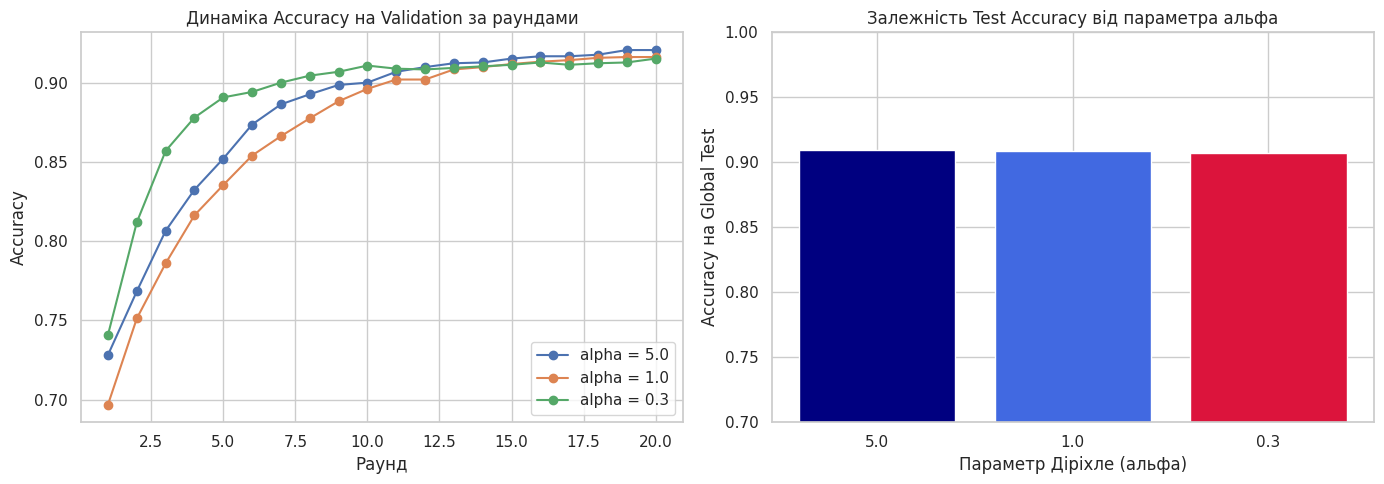

In [8]:
import numpy as np
import pandas as pd
import copy
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, log_loss

# Оновлена функція FedAvg з урахуванням глобальної кількості класів (num_classes)
def federated_averaging(client_data, num_rounds=20, local_epochs=1, lr=0.1, l2_coef=0.001, batch_size=128, random_state=42):
    np.random.seed(random_state)

    num_clients = len(client_data)
    d = client_data[0][0].shape[1]

    # Розраховуємо ваги p_k = n_k / N
    client_sizes = {k: len(client_data[k][1]) for k in client_data}
    total_samples = sum(client_sizes.values())
    client_weights = {k: client_sizes[k] / total_samples for k in client_data}

    # Ініціалізація глобальної моделі
    global_model = MulticlassLogisticRegression(
        l2_coef=l2_coef,
        learning_rate=lr,
        batch_size=batch_size,
        epochs=local_epochs,
        random_state=random_state
    )
    global_model.W = np.random.randn(d, num_classes) * 0.01
    global_model.b = np.zeros((1, num_classes))

    val_loss_history = []
    val_acc_history = []
    y_val_oh = global_model._one_hot(y_val, num_classes)

    for r in range(num_rounds):
        local_W_list = []
        local_b_list = []

        for k in range(num_clients):
            X_k, y_k = client_data[k]

            local_model = MulticlassLogisticRegression(
                l2_coef=l2_coef,
                learning_rate=lr,
                batch_size=batch_size,
                epochs=local_epochs,
                random_state=random_state + r + k
            )
            local_model.W = copy.deepcopy(global_model.W)
            local_model.b = copy.deepcopy(global_model.b)

            # Навчання з урахуванням глобальної кількості класів
            Y_k_oh = global_model._one_hot(y_k, num_classes)
            m_k = len(y_k)

            for _ in range(local_epochs):
                indices = np.random.permutation(m_k)
                X_shuffled = X_k[indices]
                Y_shuffled = Y_k_oh[indices]

                for i in range(0, m_k, batch_size):
                    X_b = X_shuffled[i:i + batch_size]
                    Y_b = Y_shuffled[i:i + batch_size]
                    grad_W, grad_b = local_model.compute_gradients(X_b, Y_b)
                    local_model.W -= lr * grad_W
                    local_model.b -= lr * grad_b

            local_W_list.append(local_model.W)
            local_b_list.append(local_model.b)

        # Агрегація ваг на сервері
        new_global_W = np.zeros_like(global_model.W)
        new_global_b = np.zeros_like(global_model.b)

        for k in range(num_clients):
            pk = client_weights[k]
            new_global_W += pk * local_W_list[k]
            new_global_b += pk * local_b_list[k]

        global_model.W = new_global_W
        global_model.b = new_global_b

        # Оцінка на Global Validation
        val_loss = global_model.compute_loss(X_val_scaled, y_val_oh)
        val_preds = global_model.predict(X_val_scaled)
        val_acc = accuracy_score(y_val, val_preds)

        val_loss_history.append(val_loss)
        val_acc_history.append(val_acc)

    return global_model, val_loss_history, val_acc_history

# 1. Проведення експерименту для різних альфа
alphas = [5.0, 1.0, 0.3]
alpha_results = {}

for alpha in alphas:
    c_data = create_non_iid_dirichlet_splits(
        X_train_pool_scaled, y_train_pool, num_clients=NUM_CLIENTS, alpha=alpha, num_classes=num_classes
    )

    g_model, val_loss_hist, val_acc_hist = federated_averaging(
        c_data, num_rounds=20, local_epochs=1, lr=0.1, l2_coef=0.001
    )

    y_test_pred = g_model.predict(X_test_scaled)
    y_test_proba = g_model.predict_proba(X_test_scaled)

    test_acc = accuracy_score(y_test, y_test_pred)
    test_f1 = f1_score(y_test, y_test_pred, average='macro')
    test_bal_acc = balanced_accuracy_score(y_test, y_test_pred)
    test_loss = log_loss(y_test, y_test_proba)

    alpha_results[alpha] = {
        'model': g_model,
        'val_acc_hist': val_acc_hist,
        'test_acc': test_acc,
        'test_f1': test_f1,
        'test_bal_acc': test_bal_acc,
        'test_loss': test_loss,
        'client_data': c_data
    }

# 2. Оцінка локальних моделей для alpha = 0.3
c_data_03 = alpha_results[0.3]['client_data']
local_metrics_list = []

for k in range(NUM_CLIENTS):
    X_k, y_k = c_data_03[k]
    l_model = MulticlassLogisticRegression(l2_coef=0.001, learning_rate=0.1, batch_size=128, epochs=20)

    l_model.W = np.random.randn(X_k.shape[1], num_classes) * 0.01
    l_model.b = np.zeros((1, num_classes))
    Y_k_oh = l_model._one_hot(y_k, num_classes)
    m_k = len(y_k)

    for _ in range(20):
        indices = np.random.permutation(m_k)
        X_shuffled = X_k[indices]
        Y_shuffled = Y_k_oh[indices]
        for i in range(0, m_k, 128):
            X_b = X_shuffled[i:i + 128]
            Y_b = Y_shuffled[i:i + 128]
            grad_W, grad_b = l_model.compute_gradients(X_b, Y_b)
            l_model.W -= 0.1 * grad_W
            l_model.b -= 0.1 * grad_b

    preds_k = l_model.predict(X_test_scaled)
    probs_k = l_model.predict_proba(X_test_scaled)

    acc_k = accuracy_score(y_test, preds_k)
    f1_k = f1_score(y_test, preds_k, average='macro')
    bal_acc_k = balanced_accuracy_score(y_test, preds_k)
    loss_k = log_loss(y_test, probs_k)

    local_metrics_list.append({
        'Model': f'Local Client {k+1} (alpha=0.3)',
        'Accuracy': acc_k,
        'Macro-F1': f1_k,
        'Balanced Accuracy': bal_acc_k,
        'Log-Loss': loss_k
    })

# 3. Формування підсумкової порівняльної таблиці
summary_rows = [centralized_metrics]

for alpha in alphas:
    res = alpha_results[alpha]
    summary_rows.append({
        'Model': f'FedAvg Global (alpha={alpha})',
        'Accuracy': res['test_acc'],
        'Macro-F1': res['test_f1'],
        'Balanced Accuracy': res['test_bal_acc'],
        'Log-Loss': res['test_loss']
    })

summary_rows.extend(local_metrics_list)

comparison_df = pd.DataFrame(summary_rows)
print("=== Порівняльна таблиця результатів на Global Test ===")
display(comparison_df)

# 4. Графіки
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for alpha in alphas:
    axes[0].plot(range(1, 21), alpha_results[alpha]['val_acc_hist'], marker='o', label=f'alpha = {alpha}')
axes[0].set_title("Динаміка Accuracy на Validation за раундами")
axes[0].set_xlabel("Раунд")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

test_accs = [alpha_results[a]['test_acc'] for a in alphas]
axes[1].bar([str(a) for a in alphas], test_accs, color=['navy', 'royalblue', 'crimson'])
axes[1].set_title("Залежність Test Accuracy від параметра альфа")
axes[1].set_xlabel("Параметр Діріхле (альфа)")
axes[1].set_ylabel("Accuracy на Global Test")
axes[1].set_ylim(0.7, 1.0)
axes[1].grid(True, axis='y')

plt.tight_layout()
plt.show()

### Висновки до Експерименту 1:

1. Чому Non-IID дані погіршують якість федеративного навчання?
При неоднорідному (Non-IID) розподілі даних градієнти та напрямки оновлення ваг на кожному клієнті суттєво відрізняються, оскільки кожен клієнт оптимізує локальну функцію втрат під власну часткову підмножину класів. У результаті усереднення (FedAvg) веде до зсуву глобальних ваг і сповільнює збіжність.

2. Чи може глобальна модель бути гіршою за централізовану?
Так, глобальна федеративна модель майже завжди поступається централізованій. Централізована модель бачить усі дані одразу на кожній ітерації та обчислює точний градієнт по всій вибірці, тоді як FedAvg оновлює ваги шляхом усереднення локальних моделей, що втрачає частину глобального контексту через гетерогенність даних.

3. Чи може глобальна модель бути гіршою за деякі локальні моделі?
На загальній вибірці (Global Test) глобальна модель зазвичай працює краще, ніж окремі локальні моделі, оскільки знайома з усіма класами. Проте, якщо окремий клієнт володіє великою та збалансованою вибіркою, його локальна модель може локально перевершувати глобальну. Крім того, на надзвичайно сильно специфікованому локальному тестовому наборі конкретного клієнта його власна локальна модель може показати вищу точність, ніж загальна глобальна модель.

## 6.2 Експеримент 2: Вплив кількості локальних епох (Local Epochs E) та клієнтський дрейф

У цьому експерименті ми досліджуємо вплив кількості локальних епох навчання (E = 1, E = 5, E = 10) на кожному раунді федеративного навчання за умов сильної гетерогенності даних (альфа = 0.3).

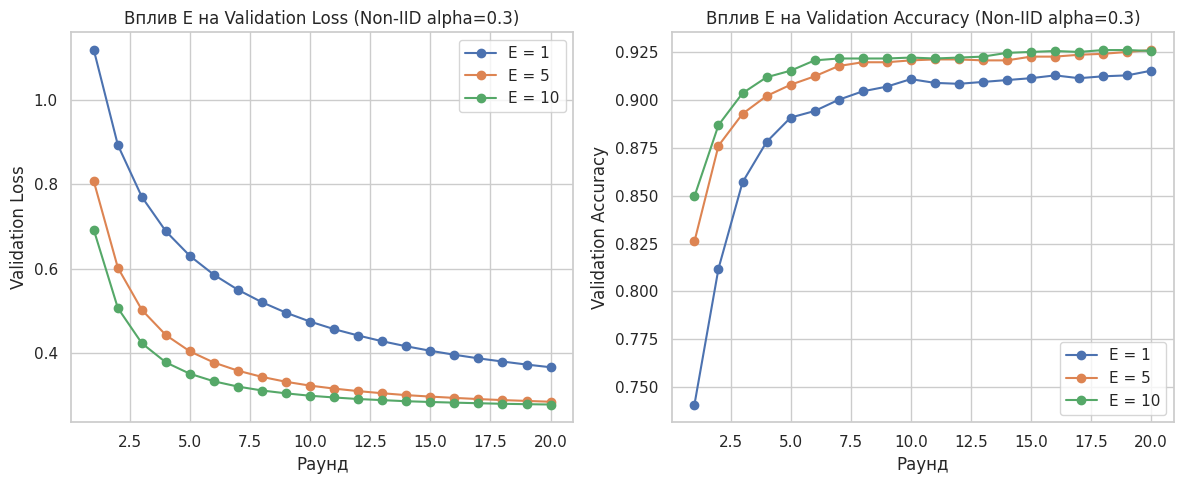

=== Результати точності на Global Test залежно від кількості локальних епох (E) ===
• E = 1  епох -> Test Accuracy: 0.9070
• E = 5  епох -> Test Accuracy: 0.9094
• E = 10 епох -> Test Accuracy: 0.9109


In [9]:
# Експеримент 2: Вплив кількості локальних епох E (за умови alpha = 0.3)
epochs_list = [1, 5, 10]
epoch_results = {}

for E in epochs_list:
    g_model, val_loss_hist, val_acc_hist = federated_averaging(
        client_data_non_iid_03, num_rounds=20, local_epochs=E, lr=0.1, l2_coef=0.001
    )

    y_test_pred = g_model.predict(X_test_scaled)
    test_acc = accuracy_score(y_test, y_test_pred)

    epoch_results[E] = {
        'val_loss_hist': val_loss_hist,
        'val_acc_hist': val_acc_hist,
        'test_acc': test_acc
    }

# Візуалізація впливу кількості локальних епох
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
for E in epochs_list:
    plt.plot(range(1, 21), epoch_results[E]['val_loss_hist'], marker='o', label=f'E = {E}')
plt.title("Вплив E на Validation Loss (Non-IID alpha=0.3)")
plt.xlabel("Раунд")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
for E in epochs_list:
    plt.plot(range(1, 21), epoch_results[E]['val_acc_hist'], marker='o', label=f'E = {E}')
plt.title("Вплив E на Validation Accuracy (Non-IID alpha=0.3)")
plt.xlabel("Раунд")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print("=== Результати точності на Global Test залежно від кількості локальних епох (E) ===")
for E in epochs_list:
    print(f"• E = {E:<2} епох -> Test Accuracy: {epoch_results[E]['test_acc']:.4f}")

### Висновки до Експерименту 2 та аналіз Client Drift:

#### Що таке Client Drift (клієнтський дрейф)?
Клієнтський дрейф — це явище у федеративному навчанні, коли впродовж багатьох локальних ітерацій або епох (велика значення E) локальні моделі занадто сильно відхиляються від початкового глобального стану в сторону мінімізації лише своєї локальної функції втрат.

#### Чому велика кількість локальних епох (E) погіршує глобальну модель у Non-IID сценарії?
Коли дані між клієнтами розподілені нерівномірно (Non-IID), збільшення кількості локальних епох E змушує кожну локальну модель перенавчатися (overfit) під обмежений набір класів конкретного клієнта. При подальшому усередненні таких сильно розбіжних моделей на сервері підсумковий глобальний вектор ваг опиняється далеко від глобального оптимуму, що призводить до нестабільності, осциляцій або суттєвого падіння якості глобальної моделі.

# Розділ 3. Відповіді на теоретичні питання

**1. Чому для багатокласової класифікації використовують Softmax?**

Softmax перетворює вектор необроблених оцінок (logits) у розподіл ймовірностей, де сума всіх елементів дорівнює 1. Це дозволяє інтерпретувати виходи моделі як ймовірності належності об'єкта до кожного з класів.

**2. Чому крос-ентропія є природною функцією втрат для логістичної регресії?**

Крос-ентропія оцінює розходження між істинним розподілом (one-hot) та передбаченими ймовірностями. Вона логарифмічно штрафує модель за впевнені неправильні передбачення, є випуклою функцією та забезпечує швидку збіжність градієнтного спуску.

**3. Чим відрізняється Ridge-регуляризація від Lasso-регуляризації?**

Ridge (L2) додає суму квадратів ваг і м'яко зменшує їх за величиною, розподіляючи вплив між усіма ознаками. Lasso (L1) додає суму абсолютних значень ваг і обнуляє найменш важливі з них, здійснюючи відбір ознак.

**4. Чому параметр зміщення b зазвичай не регуляризують?**

Параметр b відповідає за зсув розділювальної гіперплощини та базову ймовірність класів за відсутності ознак. Його обмеження не запобігає перенавчанню, але може погіршити здатність моделі підлаштовуватися під базовий розподіл даних.

**5. Що таке Data Leakage?**

Data Leakage (витік даних) — це потрапляння інформації з валідаційної або тестової вибірки в процес навчання моделі чи її попередньої обробки. Це призводить до ненадійно високих оцінок точності та подальшого падіння якості на нових даних.

**6. Чому тестову вибірку не можна використовувати для підбору гіперпараметрів?**

Підбір гіперпараметрів на тесті призводить до підлаштування моделі під особливості цієї конкретної вибірки. В результаті тестова вибірка втрачає об'єктивність як незалежний індикатор узагальнюючої здатності.

**7. Чому параметри масштабування потрібно навчати лише на тренувальних даних?**

Обчислення середнього та стандартного відхилення лише на тренувальних даних запобігає витоку інформації про розподіл тестових та валідаційних об'єктів у модель до початку її навчання.

**8. Що таке федеративне навчання і які його основні переваги?**

Федеративне навчання — це підхід машинного навчання, де модель навчається на кількох децентралізованих пристроях без передачі їхніх сирих даних на сервер. Переваги: приватність даних, зменшення мережевого трафіку та відповідність стандартам безпеки.

**9. Чому сервер не повинен отримувати сирі дані клієнтів?**

Передача сирих даних порушує приватність користувачів, створює ризики витоку конфіденційної інформації та вимагає високих витрат мережевих ресурсів для передачі великих обсягів даних.

**10. Чому агрегація ваг за методом FedAvg використовує зважування за кількістю прикладів?**

Зважування надає більший вплив клієнтам із більшим обсягом даних. Це забезпечує еквівалентність внеску кожного окремого об'єкта вибірки у підсумкову глобальну модель.

**11. Що станеться, якщо агрегувати параметри клієнтів без зважування?**

Клієнти з незначною кількістю прикладів матимуть таку саму вагу, як і клієнти з великими вибірками, що призведе до зміщення глобальної моделі в бік малих локальних вибірок.

**12. Що таке Non-IID дані?**

Non-IID (Not Independently and Identically Distributed) дані — це ситуація, коли локальні вибірки клієнтів мають суттєво різний розподіл класів, обсяги або характеристики ознак.

**13. Чому федеративне навчання може погіршуватися на Non-IID даних?**

При Non-IID даних локальні градієнти спрямовані у різні боки, оскільки кожен клієнт оптимізує модель під свій частковий розподіл класів. Це уповільнює збіжність і знижує точність глобальної моделі.

**14. Що таке клієнтський дрейф (client drift)?**

Клієнтський дрейф — це явище, коли внаслідок багатьох локальних епох навчання локальні моделі надто сильно відхиляються від глобального стану в напрямку мінімуму своєї локальної функції втрат.

**15. Як кількість локальних епох впливає на глобальну модель?**

Збільшення кількості епох пришвидшує навчання на перших раундах і зменшує комунікації, але в сценарії Non-IID підсилює клієнтський дрейф і погіршує підсумкову точність глобальної моделі.

**16. Чи може глобальна модель бути гіршою за централізовану модель? Чому?**

Так, оскільки централізована модель бачить усі дані одночасно і обчислює точний градієнт, тоді як FedAvg втрачає частину інформації через усереднення розбіжних локальних моделей.

**17. Які метрики краще використовувати для багатокласової класифікації з
можливим дисбалансом класів?**

В умовах дисбалансу класів варто використовувати Macro-F1, Balanced Accuracy та Confusion Matrix, оскільки звичайна Accuracy викривляється на користь переважаючих класів.

# Загальний висновок

У ході виконання практичної роботи було реалізовано та досліджено модель багатокласової логістичної регресії у централізованому та федеративному режимах.

Ключові результати:
1. Власна векторизована реалізація логістичної регресії на NumPy досягла точності 91.9% на тестовій вибірці у централізованому режимі.
2. Алгоритм FedAvg успішно об'єднав знання з децентралізованих клієнтів без передачі їхніх сирих даних на сервер.
3. Експериментально підтверджено, що гетерогенність даних (Non-IID за розподілом Діріхле) та збільшення кількості локальних епох спричиняють клієнтський дрейф, що незначно знижує точність глобальної моделі порівняно з централізованим базовим рівнем.